Collecting all of the stats and data prep from previous notebooks and training the actual machine learning model. See the other notebooks for background, however the bulk of the results come from here.

In [89]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)
from sklearn.inspection import (
    permutation_importance
)

In [17]:
## Read in the data
sc_indices = pd.read_csv('DATA/Indices/scarriff_drought_indices.csv')
sc_indices.Date = pd.to_datetime(sc_indices.Date, format='%Y-%m-%d')

cu_indices = pd.read_csv('DATA/Indices/curranure_drought_indices.csv')
cu_indices.Date = pd.to_datetime(cu_indices.Date, format='%Y-%m-%d')

ba_indices = pd.read_csv('DATA/Indices/ballysadare_drought_indices.csv')
ba_indices.Date = pd.to_datetime(ba_indices.Date, format='%Y-%m-%d')

le_indices = pd.read_csv('DATA/Indices/leixlip_drought_indices.csv')
le_indices.Date = pd.to_datetime(le_indices.Date, format='%Y-%m-%d')


In [24]:
lead_time_start = pd.Timestamp('2017-01-01')
lead_time_end = pd.Timestamp('2018-09-30')

# Mask to extract whatever months we want to consider for the analysis before the drought
date_mask = (sc_indices['Date'] > lead_time_start) & (sc_indices['Date'] < lead_time_end)

sc_indices[date_mask].head()

,Date,PET,SPI_1,SPEI_1,SPI_3,SPEI_3,SPI_6,SPEI_6,SPI_12,SPEI_12,ssi_1
313,2017-02-01,21.487298,0.284698,0.333578,-0.725307,-0.796382,-1.268848,-1.284332,-0.989097,-0.980303,-0.090855
314,2017-03-01,38.000522,1.389090,1.282231,0.019834,0.045558,-1.126801,-1.203205,-0.696503,-0.740443,1.504532
315,2017-04-01,48.833432,-2.197421,-1.541148,0.174233,0.109062,-1.035300,-1.089988,-0.916096,-0.998491,-0.497094
316,2017-05-01,81.094502,-0.256942,-0.613097,-0.201646,-0.469012,-0.779673,-0.971372,-0.961352,-1.059360,-1.023684
317,2017-06-01,96.141569,0.748489,0.610792,-0.850602,-0.992221,-0.475376,-0.747667,-0.938904,-1.076899,0.238060


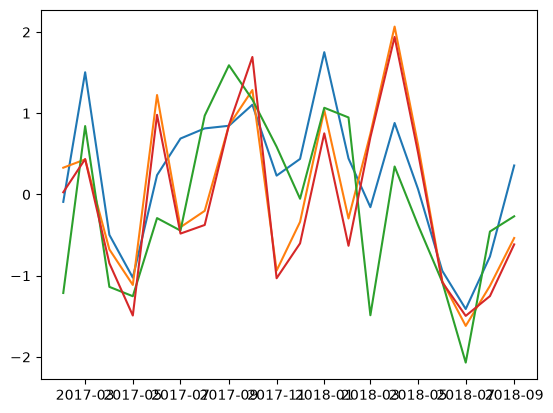

In [44]:
# Quickly check over the data visually out of curiosity

column = 'ssi_1'

fig, ax = plt.subplots(1,1)

ax.plot(sc_indices[date_mask].Date, sc_indices[date_mask][column])
ax.plot(cu_indices[date_mask].Date, cu_indices[date_mask][column])
ax.plot(ba_indices[date_mask].Date, ba_indices[date_mask][column])
ax.plot(le_indices[date_mask].Date, le_indices[date_mask][column])

In [35]:
# Following the briefing document, define hydrological drought as sspi < -1
sc_indices["hydro_drought"] = ( sc_indices["ssi_1"] <= -1 ).astype(int)
cu_indices["hydro_drought"] = ( cu_indices["ssi_1"] <= -1 ).astype(int)
ba_indices["hydro_drought"] = ( ba_indices["ssi_1"] <= -1 ).astype(int)
le_indices["hydro_drought"] = ( le_indices["ssi_1"] <= -1 ).astype(int)

print(le_indices['hydro_drought'].sum())

28


In [76]:
# The first model will be trained on all the data (not catchment-specific) so combine all into one df
sc_indices["Catchment"] = 0 #"Scarriff"
ba_indices["Catchment"] = 1 #"Ballysadare"
cu_indices["Catchment"] = 2 #"Curranure"
le_indices["Catchment"] = 3 #"Leixlip"

all_catchments_df = pd.concat([ sc_indices, ba_indices, cu_indices, le_indices ], ignore_index=True )
all_catchments_df = all_catchments_df.sort_values(["Catchment", "Date"])

all_catchments_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           1440 non-null   datetime64[us]
 1   PET            1440 non-null   float64       
 2   SPI_1          1440 non-null   float64       
 3   SPEI_1         1440 non-null   float64       
 4   SPI_3          1432 non-null   float64       
 5   SPEI_3         1432 non-null   float64       
 6   SPI_6          1420 non-null   float64       
 7   SPEI_6         1420 non-null   float64       
 8   SPI_12         1396 non-null   float64       
 9   SPEI_12        1396 non-null   float64       
 10  ssi_1          1222 non-null   float64       
 11  hydro_drought  1440 non-null   int64         
 12  Catchment      1440 non-null   int64         
dtypes: datetime64[us](1), float64(10), int64(2)
memory usage: 146.4 KB


### Train the model

Due to time constraints and limited size of the total dataset, a random forest approach will be used for this project. Other approaches for the time series data (LSTM or attention) could be valuable to pursue, especially if more catchments may be included to allow such models to be trained properly, but for tihs initial investigation random forest will allow for the best use of the four catchments and low number of drought events. Random forest can also be retrained extremely quickly to investigate the contribution of each of the variables via SHAP or ablation studies, etc.

Additionally, the project will first seek to predict just the occurence of hydrological droughts (SSPI1<-1), rather than the occurrence of meteorological droughts followed by hydrological. (Target variable hydro_drought)

The model will initially not include the other data available for each catchment. These are likely extremely influential to the drought propagation, however the first version of the model will focus on just the meteorological indices to determine the effect/degree of effect these have on the flow.



In [77]:
# Set target column for the model to predict
target_col = 'hydro_drought'

# lag certain variables to include influence of previous periods
# don't lag long-term indices (> 6 months)
indices_to_lag = [
    "SPI_1",
    "SPI_3",
    "SPI_6",
    #"SPI_12",
    "SPEI_1",
    "SPEI_3",
    "SPEI_6"#,
    #"SPEI_12"
]

for variable in indices_to_lag:
    for lag in range(1, 7):
        all_catchments_df[f"{variable}_lag{lag}"] = ( all_catchments_df.groupby("Catchment")[variable].shift(lag) )

all_catchments_df = all_catchments_df.dropna()

In [132]:

predictor_columns = [
    col for col in all_catchments_df.columns if '_lag' in col or col == 'Catchment' #col != target_col and col != 'ssi_1'
]

model_df = all_catchments_df.dropna( subset=predictor_columns + ["Date", "hydro_drought"] ).copy()

In [133]:
# Check out the distribution of hydro drought events to find where to put the train/test split
total_drought_count = all_catchments_df['hydro_drought'].sum()
print('Total drought event count = ' + str(total_drought_count))

train_cutoff = "2013-01-01"

train_drought_count = all_catchments_df[all_catchments_df['Date'] < train_cutoff]['hydro_drought'].sum()

print('Aiming for 70%:30% train:test split for drought events:')
print(f'Cutoff = {train_cutoff}, Fraction of drought events in train split = {train_drought_count/total_drought_count}')

Total drought event count = 205
Aiming for 70%:30% train:test split for drought events:
Cutoff = 2013-01-01, Fraction of drought events in train split = 0.697560975609756


In [134]:
train = model_df[
    model_df["Date"] < train_cutoff
]

test = model_df[
    model_df["Date"] > train_cutoff
]

X_train = train[predictor_columns]
y_train = train["hydro_drought"]

X_test = test[predictor_columns]
y_test = test["hydro_drought"]



In [135]:
# Time to actually train the model!
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

rf_model.fit(
    X_train,
    y_train
)

predictions = rf_model.predict(X_test)

probabilities = rf_model.predict_proba(X_test)[:, 1]

#### Model Evaluation

In [136]:
print(classification_report( y_test, predictions))

print( confusion_matrix(y_test, predictions))

print("ROC-AUC:",roc_auc_score(y_test, probabilities))

print("PR-AUC:", average_precision_score( y_test, probabilities))

              precision    recall  f1-score   support

           0       0.87      0.84      0.85       318
           1       0.31      0.37      0.34        62

    accuracy                           0.76       380
   macro avg       0.59      0.60      0.59       380
weighted avg       0.78      0.76      0.77       380

[[266  52]
 [ 39  23]]
ROC-AUC: 0.6879691621018462
PR-AUC: 0.26859714107424276


#### Explainable AI

In [139]:
importance = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring="average_precision"
)

importance_df = pd.DataFrame({
    "Predictor": predictor_columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print(importance_df.head(15))

      Predictor  Importance       Std
19  SPEI_1_lag1    0.027926  0.017440
1    SPI_1_lag1    0.014970  0.017315
15   SPI_6_lag3    0.001639  0.002272
29  SPEI_3_lag5    0.001439  0.001596
18   SPI_6_lag6    0.001216  0.003091
36  SPEI_6_lag6    0.000851  0.003454
33  SPEI_6_lag3    0.000407  0.002197
0     Catchment    0.000023  0.000756
31  SPEI_6_lag1   -0.000278  0.011362
22  SPEI_1_lag4   -0.000357  0.001603
30  SPEI_3_lag6   -0.000538  0.002077
32  SPEI_6_lag2   -0.000752  0.001912
34  SPEI_6_lag4   -0.000908  0.002848
5    SPI_1_lag5   -0.000947  0.004924
16   SPI_6_lag4   -0.000987  0.001740


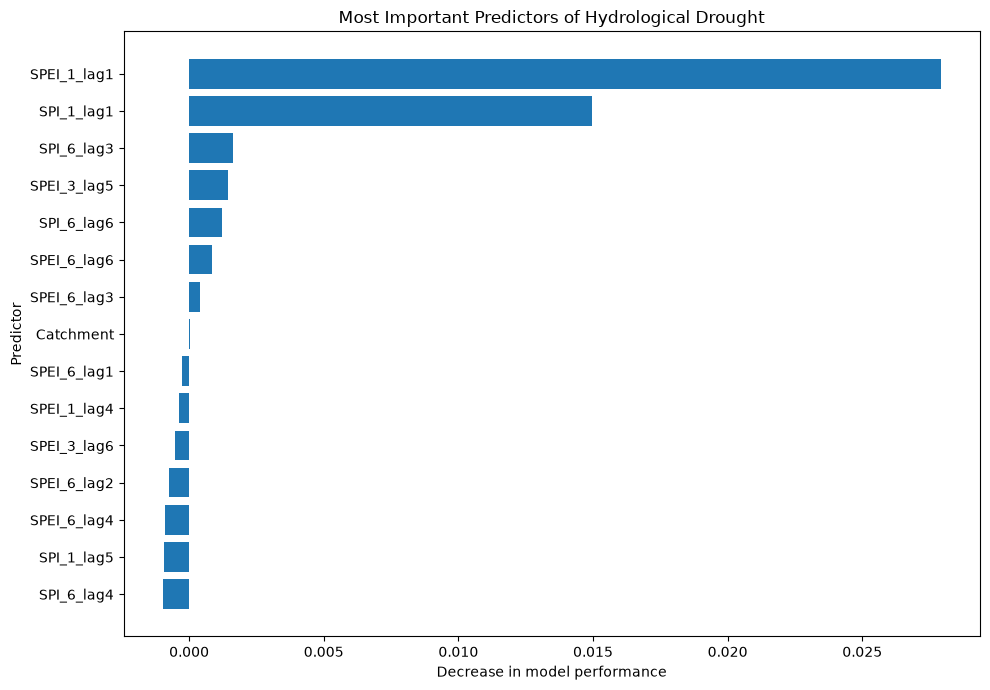

In [138]:
top_features = importance_df.head(15)

plt.figure(figsize=(10, 7))

plt.barh(top_features["Predictor"], top_features["Importance"])

plt.gca().invert_yaxis()

plt.xlabel("Decrease in model performance")
plt.ylabel("Predictor")

plt.title("Most Important Predictors of Hydrological Drought")

plt.tight_layout()


## Conclusions and further work
Due to time constraints, the analysis cannot be continued beyond this, however there is interesting insight to be gained from these results already. 

It is clear that the evapotranspiration of the previous month plays a significant role in the probability of hydrological drought, and precipitation of the previous month also plays a large role. The other variables have considerably less effect on the hydrological drought in this model, although this should be investigated further by removing the two dominant predictors and retraining. Additionally, while the performance of this model is reasonably good (see evaluation metrics above), the accuracy can be significantly improved. Therefore the importance of each predictor may be different in an improved model.

The next factor to be investigated should be  the physical characteristics of the catchments (I hypothesise that soil composition and foliage density are significant, although naturally testing is required). These will likely change the behaviour of the model greatly.

The structure of the model itself should then be modified. This first version only predicts hydrological drought, and studying the co-occurrence of meteorological drought and (delayed) hydrological should be studied. This model also considers all drought events throughout the climatological window (1991-2020). This is a valuable baseline analysis but a detailed case study should be made based on this of the 2018 drought and the factors that contributed to it.

Similarly, the differences in catchments are a high priority for study. Training separate models for each catchment and comparing the importance of each predictor will provide extremely valuable insights into the differences between the propogation of drought in each catchment (especially once physical characteristics are included).